In [ ]:

!pip -q install -U git+https://github.com/huggingface/transformers
!pip -q install -U accelerate bitsandbytes datasets
!pip -q install -U sympy


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
!pip uninstall -y cudf-cu13
!pip install -q "pyarrow>=24"

Found existing installation: cudf-cu13 26.6.0
Uninstalling cudf-cu13-26.6.0:
  Successfully uninstalled cudf-cu13-26.6.0


In [ ]:
!pip install -q "pyarrow>=24"

In [ ]:
import torch
import transformers
import sympy
import pyarrow
from datasets import load_dataset
from transformers import AutoProcessor, Qwen2AudioForConditionalGeneration

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("SymPy:", sympy.__version__)
print("PyArrow:", pyarrow.__version__)
print("GPU available:", torch.cuda.is_available())
print("All imports successful!")

PyTorch: 2.14.1+cu130
Transformers: 5.24.0.dev0
SymPy: 1.14.0
PyArrow: 26.0.1
GPU available: True
All imports successful!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd

path = "/content/drive/MyDrive/qwen_meld_full_results.csv"

if os.path.exists(path):
    df = pd.read_csv(path)
    print("CSV FOUND")
    print("Total saved rows:", len(df))
    print("\nStatus breakdown:")
    print(df["status"].value_counts(dropna=False))
    display(df.head())
else:
    print("CSV NOT FOUND")
    print("We will create a new results file.")

Mounted at /content/drive
CSV FOUND
Total saved rows: 3293

Status breakdown:
status
ok         3232
invalid      61
Name: count, dtype: int64


,dialogue_id,utterance_id,actual,condition,raw_response,prediction,status,model
0,0,2,neutral,audio_only,neutral,neutral,ok,Qwen/Qwen2-Audio-7B-Instruct
1,0,2,neutral,audio_context,angry,anger,ok,Qwen/Qwen2-Audio-7B-Instruct
2,0,2,neutral,text_only,joy,joy,ok,Qwen/Qwen2-Audio-7B-Instruct
3,0,2,neutral,text_context,joy,joy,ok,Qwen/Qwen2-Audio-7B-Instruct
4,1,2,joy,audio_only,angry,anger,ok,Qwen/Qwen2-Audio-7B-Instruct


In [ ]:
from datasets import load_dataset
from collections import defaultdict

# Load MELD test split
ds = load_dataset("TwinkStart/MELD", split="test")

# Exclude the 10 pilot samples
pilot_ids = [
    (25, 10), (128, 8), (119, 5), (203, 9), (64, 13),
    (212, 6), (266, 11), (199, 9), (76, 11), (188, 5)
]
pilot_set = set(pilot_ids)

# Group utterances by dialogue
dialogues = defaultdict(list)

for idx, row in enumerate(ds):
    dialogue_id = int(row["Dialogue_ID"])
    utterance_id = int(row["Utterance_ID"])

    dialogues[dialogue_id].append({
        "idx": idx,
        "utterance_id": utterance_id
    })

# Rebuild eligible targets
eligible_targets = []

for dialogue_id, turns in dialogues.items():
    turns.sort(key=lambda x: x["utterance_id"])

    for position in range(2, len(turns)):
        target = turns[position]
        context1 = turns[position - 2]
        context2 = turns[position - 1]

        key = (dialogue_id, target["utterance_id"])

        if key in pilot_set:
            continue

        eligible_targets.append({
            "dialogue_id": dialogue_id,
            "utterance_id": target["utterance_id"],
            "target_idx": target["idx"],
            "context1_idx": context1["idx"],
            "context2_idx": context2["idx"]
        })

print("MELD loaded:", len(ds))
print("Eligible targets:", len(eligible_targets))
print("Expected predictions:", len(eligible_targets) * 4)

README.md:   0%|          | 0.00/2.90k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

data/test-00000-of-00017.parquet: reconstructing file:   0%|          |  0.00B / 84.0MB            

data/test-00000-of-00017.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00017.parquet: reconstructing file:   0%|          |  0.00B / 89.2MB            

... (29 outputs left out)

data/test-00016-of-00017.parquet: reconstructing file:   0%|          |  0.00B / 85.6MB            

data/test-00016-of-00017.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/2610 [00:00<?, ? examples/s]

MELD loaded: 2610
Eligible targets: 2052
Expected predictions: 8208


In [ ]:
from transformers.utils import is_bitsandbytes_available

print("BitsAndBytes available:", is_bitsandbytes_available())

BitsAndBytes available: True


In [ ]:


import torch
from transformers import (
    AutoProcessor,
    Qwen2AudioForConditionalGeneration,
    BitsAndBytesConfig
)

model_id = "Qwen/Qwen2-Audio-7B-Instruct"

print("GPU:", torch.cuda.get_device_name(0))
print("Loading processor...")

processor = AutoProcessor.from_pretrained(model_id)

print("Processor loaded.")
print("Loading Qwen model in 4-bit...")

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = Qwen2AudioForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16
)

model.eval()

print("\nQwen model loaded successfully!")
print("Model:", model_id)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

GPU: Tesla T4
Loading processor...


preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/853 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/638k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/230 [00:00<?, ?B/s]


Qwen model loaded successfully!
Model: Qwen/Qwen2-Audio-7B-Instruct
GPU memory allocated: 5.82 GB


In [ ]:
import re
import time
import numpy as np
import pandas as pd

EMOTIONS = [
    "anger", "disgust", "fear", "joy",
    "neutral", "sadness", "surprise"
]

ALIASES = {
    "angry": "anger",
    "happy": "joy"
}

audio_only_instruction = """
Identify the emotion expressed in the TARGET audio utterance.

Choose exactly one label:
anger, disgust, fear, joy, neutral, sadness, surprise.

Return only the emotion label.
"""

audio_context_instruction = """
The following three audio segments are from the same conversation,
in chronological order.

Audio 1: Previous utterance 1.
Audio 2: Previous utterance 2.
Audio 3: TARGET utterance.

Use the first two audio segments as conversational context.
Classify the emotion expressed in Audio 3 only.

Choose exactly one label:
anger, disgust, fear, joy, neutral, sadness, surprise.

Return only the emotion label.
"""

text_only_instruction = """
Identify the emotion expressed in the TARGET utterance.

TARGET UTTERANCE:
{target}

Choose exactly one label:
anger, disgust, fear, joy, neutral, sadness, surprise.

Return only the emotion label.
"""

text_context_instruction = """
The following utterances are from the same conversation,
in chronological order.

PREVIOUS UTTERANCE 1:
{context1}

PREVIOUS UTTERANCE 2:
{context2}

TARGET UTTERANCE:
{target}

Use the previous utterances as conversational context.
Classify the emotion expressed in the TARGET UTTERANCE only.

Choose exactly one label:
anger, disgust, fear, joy, neutral, sadness, surprise.

Return only the emotion label.
"""

print("Emotion labels restored.")
print("All four experimental prompts restored.")

Emotion labels restored.
All four experimental prompts restored.


In [ ]:
def get_audio_conversation(instruction, audio_list):
    content = []

    for audio in audio_list:
        content.append({
            "type": "audio",
            "audio": audio
        })

    content.append({
        "type": "text",
        "text": instruction
    })

    return [{
        "role": "user",
        "content": content
    }]


def get_text_conversation(prompt):
    return [{
        "role": "user",
        "content": [{
            "type": "text",
            "text": prompt
        }]
    }]


def extract_emotion(response):
    response = response.lower().strip()

    match = re.search(
        r'target utterance.*?\bis\s+["\']?(anger|disgust|fear|joy|neutral|sadness|surprise)',
        response,
        re.DOTALL
    )

    if match:
        return match.group(1)

    match = re.search(
        r'emotion.*?\bis\s+["\']?(anger|disgust|fear|joy|neutral|sadness|surprise)',
        response,
        re.DOTALL
    )

    if match:
        return match.group(1)

    cleaned = re.sub(r"[^a-z]+", " ", response)
    words = cleaned.split()

    found = [
        ALIASES.get(word, word)
        for word in words
        if word in EMOTIONS or word in ALIASES
    ]

    if len(set(found)) == 1:
        return found[0]

    return "invalid"


def generate_prediction(conversation, audio_input=None):
    text_prompt = processor.apply_chat_template(
        conversation,
        add_generation_prompt=True,
        tokenize=False
    )

    if audio_input is not None:
        inputs = processor(
            text=text_prompt,
            audio=audio_input,
            sampling_rate=16000,
            return_tensors="pt",
            padding=True
        )
    else:
        inputs = processor(
            text=text_prompt,
            return_tensors="pt"
        )

    inputs = inputs.to(model.device)

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=50,
            do_sample=False
        )

    generated_ids = generated_ids[:, inputs.input_ids.shape[1]:]

    raw_response = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0].strip()

    prediction = extract_emotion(raw_response)

    return raw_response, prediction


print("Conversation functions restored.")
print("Emotion parser restored.")
print("Prediction function restored.")

Conversation functions restored.
Emotion parser restored.
Prediction function restored.


In [ ]:
# Select the first eligible target
sample = eligible_targets[0]

target_row = ds[sample["target_idx"]]
context1_row = ds[sample["context1_idx"]]
context2_row = ds[sample["context2_idx"]]

target_text = target_row["Utterance"]
context1_text = context1_row["Utterance"]
context2_text = context2_row["Utterance"]

target_audio = np.array(target_row["audio"]["array"], dtype=np.float32)
context1_audio = np.array(context1_row["audio"]["array"], dtype=np.float32)
context2_audio = np.array(context2_row["audio"]["array"], dtype=np.float32)

actual = str(target_row["Emotion"]).lower()

print("Dialogue:", sample["dialogue_id"])
print("Utterance:", sample["utterance_id"])
print("Target:", target_text)
print("Actual emotion:", actual)

# 1. Audio only
conversation = get_audio_conversation(
    audio_only_instruction,
    [target_audio]
)
raw1, pred1 = generate_prediction(conversation, [target_audio])

# 2. Audio + context
conversation = get_audio_conversation(
    audio_context_instruction,
    [context1_audio, context2_audio, target_audio]
)
raw2, pred2 = generate_prediction(
    conversation,
    [context1_audio, context2_audio, target_audio]
)

# 3. Text only
conversation = get_text_conversation(
    text_only_instruction.format(target=target_text)
)
raw3, pred3 = generate_prediction(conversation)

# 4. Text + context
conversation = get_text_conversation(
    text_context_instruction.format(
        context1=context1_text,
        context2=context2_text,
        target=target_text
    )
)
raw4, pred4 = generate_prediction(conversation)

print("\nRESULTS")
print("Audio only:", pred1, "|", raw1)
print("Audio + context:", pred2, "|", raw2)
print("Text only:", pred3, "|", raw3)
print("Text + context:", pred4, "|", raw4)

Dialogue: 0
Utterance: 2
Target: Y'know what?
Actual emotion: neutral

RESULTS
Audio only: neutral | neutral
Audio + context: anger | angry
Text only: joy | joy
Text + context: joy | joy


In [ ]:
import pandas as pd

results_path = "/content/drive/MyDrive/qwen_meld_full_results.csv"

saved = pd.read_csv(results_path)

conditions = [
    "audio_only",
    "audio_context",
    "text_only",
    "text_context"
]

valid_emotions = {
    "anger", "disgust", "fear", "joy",
    "neutral", "sadness", "surprise"
}

successful = saved[
    (saved["status"] == "ok") &
    (saved["prediction"].isin(valid_emotions))
]

completed_keys = set(
    zip(
        successful["dialogue_id"],
        successful["utterance_id"],
        successful["condition"]
    )
)

print("Saved rows:", len(saved))
print("Successful rows:", len(successful))
print("Unique successful predictions:", len(completed_keys))
print("Invalid/error rows:", len(saved) - len(successful))
print("Remaining predictions:", 8208 - len(completed_keys))
print("Duplicate successful rows:", len(successful) - len(completed_keys))

Saved rows: 3293
Successful rows: 3232
Unique successful predictions: 3232
Invalid/error rows: 61
Remaining predictions: 4976
Duplicate successful rows: 0


In [ ]:

import os
import csv
import shutil
import time
import numpy as np
import pandas as pd
from datetime import datetime

results_path = "/content/drive/MyDrive/qwen_meld_full_results.csv"
local_path = "/content/qwen_meld_working.csv"

conditions = [
    "audio_only",
    "audio_context",
    "text_only",
    "text_context"
]

valid_emotions = {
    "anger", "disgust", "fear", "joy",
    "neutral", "sadness", "surprise"
}

columns = [
    "dialogue_id", "utterance_id", "actual", "condition",
    "raw_response", "prediction", "status", "model"
]

# 1. Check the existing file
if not os.path.exists(results_path):
    raise FileNotFoundError(
        "Existing CSV not found. Stop here; do not start a new file."
    )

# 2. Create a backup before making changes
backup_path = results_path + ".backup_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
shutil.copy2(results_path, backup_path)

print("Backup created:", backup_path)

# 3. Load existing data and check its structure
saved = pd.read_csv(results_path)

missing_columns = [c for c in columns if c not in saved.columns]
if missing_columns:
    raise ValueError(f"CSV is missing columns: {missing_columns}")

# Remove accidental pandas index columns, if present
saved = saved[columns].copy()

# Create a clean local working copy
saved.to_csv(local_path, index=False)

def get_completed_keys(df):
    completed = set()

    for _, row in df.iterrows():
        prediction = str(row["prediction"]).strip().lower()

        if str(row["status"]).strip().lower() == "ok" and prediction in valid_emotions:
            completed.add((
                int(row["dialogue_id"]),
                int(row["utterance_id"]),
                str(row["condition"])
            ))

    return completed

completed_keys = get_completed_keys(saved)

print("Existing CSV rows:", len(saved))
print("Successful predictions:", len(completed_keys))
print("Remaining predictions:", 8208 - len(completed_keys))

# 4. Checkpoint function: copy local progress to Google Drive
def save_checkpoint():
    temp_path = results_path + ".tmp"
    shutil.copy2(local_path, temp_path)
    os.replace(temp_path, results_path)

    # Verify the checkpoint
    check = pd.read_csv(results_path)
    print("CHECKPOINT SAVED | Rows in Drive:", len(check))

# 5. Start resumable evaluation
processed_now = 0
errors_now = 0
start_time = time.time()

with open(local_path, "a", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)

    for sample in eligible_targets:

        dialogue_id = int(sample["dialogue_id"])
        utterance_id = int(sample["utterance_id"])

        # Skip targets whose four conditions are already successful
        if all(
            (dialogue_id, utterance_id, condition) in completed_keys
            for condition in conditions
        ):
            continue

        target_row = ds[sample["target_idx"]]
        context1_row = ds[sample["context1_idx"]]
        context2_row = ds[sample["context2_idx"]]

        actual = str(target_row["Emotion"]).lower().strip()
        actual = ALIASES.get(actual, actual)

        target_text = target_row["Utterance"]
        context1_text = context1_row["Utterance"]
        context2_text = context2_row["Utterance"]

        target_audio = np.array(
            target_row["audio"]["array"], dtype=np.float32
        )
        context1_audio = np.array(
            context1_row["audio"]["array"], dtype=np.float32
        )
        context2_audio = np.array(
            context2_row["audio"]["array"], dtype=np.float32
        )

        for condition in conditions:

            key = (dialogue_id, utterance_id, condition)

            if key in completed_keys:
                continue

            raw_response = ""
            prediction = "invalid"
            status = "invalid"

            try:
                if condition == "audio_only":
                    conversation = get_audio_conversation(
                        audio_only_instruction, [target_audio]
                    )
                    raw_response, prediction = generate_prediction(
                        conversation, [target_audio]
                    )

                elif condition == "audio_context":
                    audios = [
                        context1_audio, context2_audio, target_audio
                    ]
                    conversation = get_audio_conversation(
                        audio_context_instruction, audios
                    )
                    raw_response, prediction = generate_prediction(
                        conversation, audios
                    )

                elif condition == "text_only":
                    conversation = get_text_conversation(
                        text_only_instruction.format(target=target_text)
                    )
                    raw_response, prediction = generate_prediction(
                        conversation
                    )

                elif condition == "text_context":
                    conversation = get_text_conversation(
                        text_context_instruction.format(
                            context1=context1_text,
                            context2=context2_text,
                            target=target_text
                        )
                    )
                    raw_response, prediction = generate_prediction(
                        conversation
                    )

                prediction = str(prediction).strip().lower()

                if prediction in valid_emotions:
                    status = "ok"

            except Exception as e:
                status = "error"
                raw_response = repr(e)
                prediction = "invalid"
                errors_now += 1
                print("ERROR:", key, repr(e))

            writer.writerow({
                "dialogue_id": dialogue_id,
                "utterance_id": utterance_id,
                "actual": actual,
                "condition": condition,
                "raw_response": raw_response,
                "prediction": prediction,
                "status": status,
                "model": "Qwen/Qwen2-Audio-7B-Instruct"
            })

            f.flush()
            processed_now += 1

            if status == "ok":
                completed_keys.add(key)

            # Save to Drive every 10 new attempts
            if processed_now % 10 == 0:
                save_checkpoint()

                print(
                    "New attempts:", processed_now,
                    "| Successful total:", len(completed_keys),
                    "| Remaining:", 8208 - len(completed_keys),
                    "| Errors:", errors_now
                )

# 6. Final checkpoint
save_checkpoint()

print("\nRUN FINISHED")
print("New attempts:", processed_now)
print("Successful predictions:", len(completed_keys))
print("Remaining:", 8208 - len(completed_keys))
print("Errors:", errors_now)
print("Time (minutes):", round((time.time() - start_time) / 60, 2))


Backup created: /content/drive/MyDrive/qwen_meld_full_results.csv.backup_20261117_083539.csv
Existing CSV rows: 3293
Successful predictions: 3232
Remaining predictions: 4976
CHECKPOINT SAVED | Rows in Drive: 3303
New attempts: 10 | Successful total: 3232 | Remaining: 4976 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3313
New attempts: 20 | Successful total: 3232 | Remaining: 4976 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3323
New attempts: 30 | Successful total: 3233 | Remaining: 4975 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3333
New attempts: 40 | Successful total: 3233 | Remaining: 4975 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3343
New attempts: 50 | Successful total: 3233 | Remaining: 4975 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3353
New attempts: 60 | Successful total: 3235 | Remaining: 4973 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3363
New attempts: 70 | Successful total: 3244 | Remaining: 4964 | Errors: 0
CHECKPOINT SAVED | Rows in Drive: 3373
New attemp

In [1]:

# ============================================
# MELD + QWEN2-AUDIO: EXPERIMENT EVALUATION
# ============================================

from google.colab import drive
drive.mount('/content/drive')

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# File location
FILE_PATH = "/content/drive/MyDrive/qwen_meld_full_results.csv"

# Output folder
OUTPUT_DIR = "/content/drive/MyDrive/MELD_Evaluation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load CSV
df = pd.read_csv(FILE_PATH)

print("CSV loaded successfully!")
print("Original rows:", len(df))
print("Columns:", df.columns.tolist())

print("\nCondition counts:")
print(df["condition"].value_counts(dropna=False))

print("\nStatus counts:")
print(df["status"].value_counts(dropna=False))

print("\nFirst five rows:")
display(df.head())


Mounted at /content/drive
CSV loaded successfully!
Original rows: 8269
Columns: ['dialogue_id', 'utterance_id', 'actual', 'condition', 'raw_response', 'prediction', 'status', 'model']

Condition counts:
condition
text_context     2092
text_only        2072
audio_only       2053
audio_context    2052
Name: count, dtype: int64

Status counts:
status
ok         8057
invalid     212
Name: count, dtype: int64

First five rows:


,dialogue_id,utterance_id,actual,condition,raw_response,prediction,status,model
0,0,2,neutral,audio_only,neutral,neutral,ok,Qwen/Qwen2-Audio-7B-Instruct
1,0,2,neutral,audio_context,angry,anger,ok,Qwen/Qwen2-Audio-7B-Instruct
2,0,2,neutral,text_only,joy,joy,ok,Qwen/Qwen2-Audio-7B-Instruct
3,0,2,neutral,text_context,joy,joy,ok,Qwen/Qwen2-Audio-7B-Instruct
4,1,2,joy,audio_only,angry,anger,ok,Qwen/Qwen2-Audio-7B-Instruct


In [2]:

# ============================================
# DATA CLEANING AND PREPARATION
# ============================================

CONDITIONS = [
    "audio_only",
    "audio_context",
    "text_only",
    "text_context"
]

LABELS = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise"
]

# Normalize emotion labels
ALIASES = {
    "angry": "anger",
    "happy": "joy",
    "sad": "sadness"
}

def normalize_emotion(value):

    if pd.isna(value):
        return None

    value = str(value).strip().lower()

    # Remove surrounding punctuation
    value = re.sub(r"^[^a-z]+|[^a-z]+$", "", value)

    # Handle common aliases
    value = ALIASES.get(value, value)

    # Only accept the seven valid labels
    if value in LABELS:
        return value

    # Handle responses containing a label in a sentence
    for label in LABELS:
        if re.search(r"\b" + label + r"\b", value):
            return label

    for alias, canonical in ALIASES.items():
        if re.search(r"\b" + alias + r"\b", value):
            return canonical

    return None


# Keep successful predictions
data = df.copy()

data["status"] = data["status"].astype(str).str.strip().str.lower()
data = data[data["status"] == "ok"].copy()

# Keep only the four experimental conditions
data = data[data["condition"].isin(CONDITIONS)].copy()

# Normalize actual and predicted emotions
data["actual_clean"] = data["actual"].apply(normalize_emotion)
data["prediction_clean"] = data["prediction"].apply(normalize_emotion)

# Remove invalid labels
data = data.dropna(
    subset=["dialogue_id", "utterance_id",
            "actual_clean", "prediction_clean"]
).copy()

# Remove any labels outside the seven classes
data = data[
    data["actual_clean"].isin(LABELS) &
    data["prediction_clean"].isin(LABELS)
].copy()

# Remove duplicate attempts
data = data.drop_duplicates(
    subset=["dialogue_id", "utterance_id", "condition"],
    keep="last"
)

# Unique target identifier
data["target_id"] = (
    data["dialogue_id"].astype(str) + "_" +
    data["utterance_id"].astype(str)
)

print("Valid prediction rows:", len(data))

print("\nRows per condition:")
print(data["condition"].value_counts())

# Check actual labels are consistent across conditions
actual_consistency = (
    data.groupby("target_id")["actual_clean"].nunique()
)

inconsistent_targets = actual_consistency[
    actual_consistency > 1
]

print("\nTargets with inconsistent actual labels:",
      len(inconsistent_targets))

# Keep targets with all four conditions
condition_counts = data.groupby("target_id")["condition"].nunique()

complete_targets = condition_counts[
    condition_counts == 4
].index

complete = data[
    data["target_id"].isin(complete_targets)
].copy()

# Exclude targets with inconsistent ground truth
valid_targets = actual_consistency[
    actual_consistency == 1
].index

complete = complete[
    complete["target_id"].isin(valid_targets)
].copy()

print("\nComplete targets across all four conditions:",
      complete["target_id"].nunique())

print("Rows in final paired dataset:", len(complete))

print("\nFinal condition counts:")
print(complete["condition"].value_counts())

# Save cleaned data
complete.to_csv(
    os.path.join(OUTPUT_DIR, "cleaned_complete_predictions.csv"),
    index=False
)

print("\nCleaned dataset saved.")


Valid prediction rows: 8057

Rows per condition:
condition
audio_context    2051
audio_only       2049
text_only        1989
text_context     1968
Name: count, dtype: int64

Targets with inconsistent actual labels: 0

Complete targets across all four conditions: 1918
Rows in final paired dataset: 7672

Final condition counts:
condition
audio_only       1918
audio_context    1918
text_only        1918
text_context     1918
Name: count, dtype: int64

Cleaned dataset saved.


In [3]:

# ============================================
# OVERALL EVALUATION METRICS
# ============================================

metric_results = []

for condition in CONDITIONS:

    subset = complete[
        complete["condition"] == condition
    ]

    y_true = subset["actual_clean"]
    y_pred = subset["prediction_clean"]

    metrics = {
        "Condition": condition,
        "Samples": len(subset),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_Precision": precision_score(
            y_true, y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true, y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true, y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }

    metric_results.append(metrics)

metrics_df = pd.DataFrame(metric_results)

print("OVERALL METRICS")
display(
    metrics_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro_Precision": "{:.4f}",
        "Macro_Recall": "{:.4f}",
        "Macro_F1": "{:.4f}"
    })
)

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "overall_metrics.csv"),
    index=False
)

print("Metrics saved.")


OVERALL METRICS


,Condition,Samples,Accuracy,Macro_Precision,Macro_Recall,Macro_F1
0,audio_only,1918,0.4567,0.4241,0.3416,0.3194
1,audio_context,1918,0.2581,0.3974,0.2920,0.2142
2,text_only,1918,0.5422,0.4401,0.4356,0.4072
3,text_context,1918,0.4249,0.3915,0.4578,0.3597


Metrics saved.


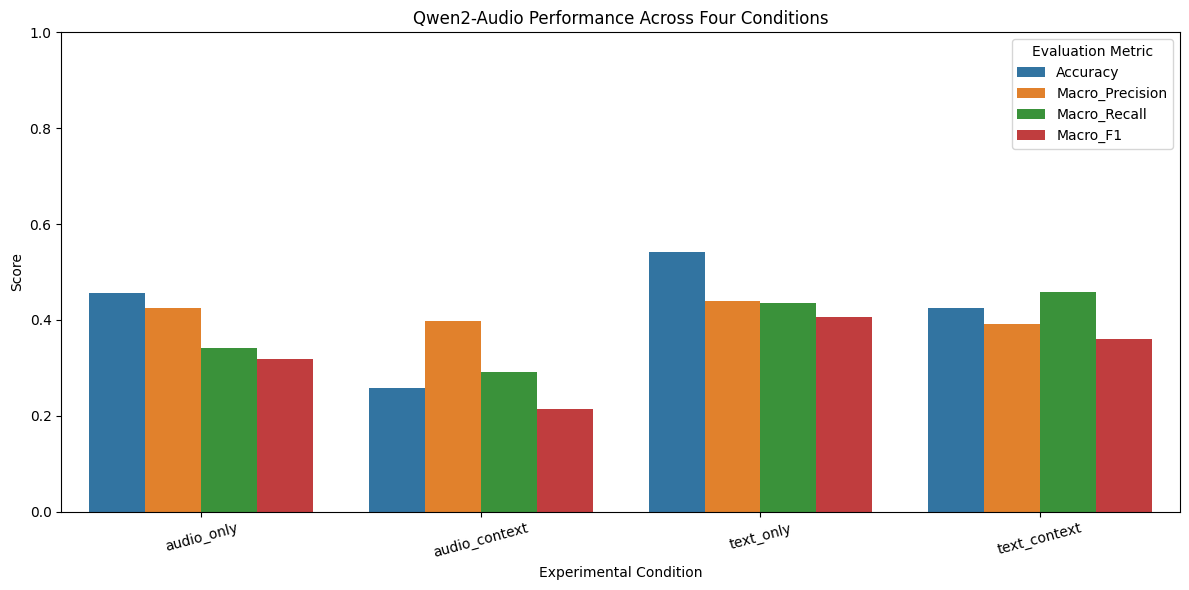

In [4]:

# ============================================
# FIGURE 1: OVERALL PERFORMANCE COMPARISON
# ============================================

plot_metrics = metrics_df.melt(
    id_vars="Condition",
    value_vars=[
        "Accuracy",
        "Macro_Precision",
        "Macro_Recall",
        "Macro_F1"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_metrics,
    x="Condition",
    y="Score",
    hue="Metric"
)

plt.title("Qwen2-Audio Performance Across Four Conditions")
plt.xlabel("Experimental Condition")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Evaluation Metric")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "figure1_overall_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Condition,Emotion,Precision,Recall,F1,Support
0,audio_only,anger,0.269,0.564,0.364,257.000000
1,audio_only,disgust,0.261,0.122,0.167,49.000000
2,audio_only,fear,0.154,0.235,0.186,34.000000
3,audio_only,joy,0.548,0.392,0.457,291.000000
4,audio_only,neutral,0.632,0.567,0.598,913.000000
5,audio_only,sadness,0.271,0.440,0.336,159.000000
6,audio_only,surprise,0.833,0.070,0.129,215.000000
7,audio_context,anger,0.183,0.860,0.302,257.000000
8,audio_context,disgust,0.556,0.102,0.172,49.000000
9,audio_context,fear,0.148,0.118,0.131,34.000000


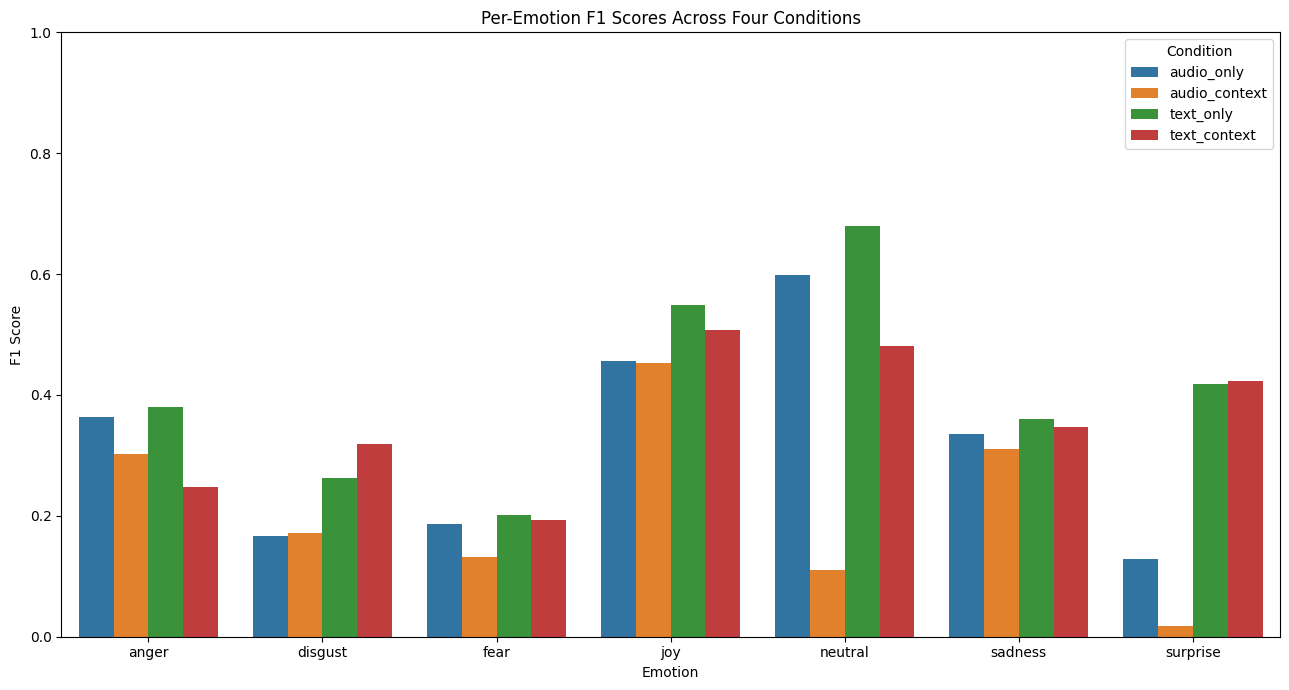

In [5]:

# ============================================
# PER-EMOTION PERFORMANCE
# ============================================

class_results = []

for condition in CONDITIONS:

    subset = complete[
        complete["condition"] == condition
    ]

    report = classification_report(
        subset["actual_clean"],
        subset["prediction_clean"],
        labels=LABELS,
        output_dict=True,
        zero_division=0
    )

    for emotion in LABELS:

        class_results.append({
            "Condition": condition,
            "Emotion": emotion,
            "Precision": report[emotion]["precision"],
            "Recall": report[emotion]["recall"],
            "F1": report[emotion]["f1-score"],
            "Support": report[emotion]["support"]
        })

class_df = pd.DataFrame(class_results)

display(
    class_df.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)

class_df.to_csv(
    os.path.join(OUTPUT_DIR, "per_emotion_metrics.csv"),
    index=False
)

# Figure 2: Per-emotion F1 scores
plt.figure(figsize=(13, 7))

sns.barplot(
    data=class_df,
    x="Emotion",
    y="F1",
    hue="Condition"
)

plt.title("Per-Emotion F1 Scores Across Four Conditions")
plt.xlabel("Emotion")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.legend(title="Condition")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "figure2_emotion_f1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


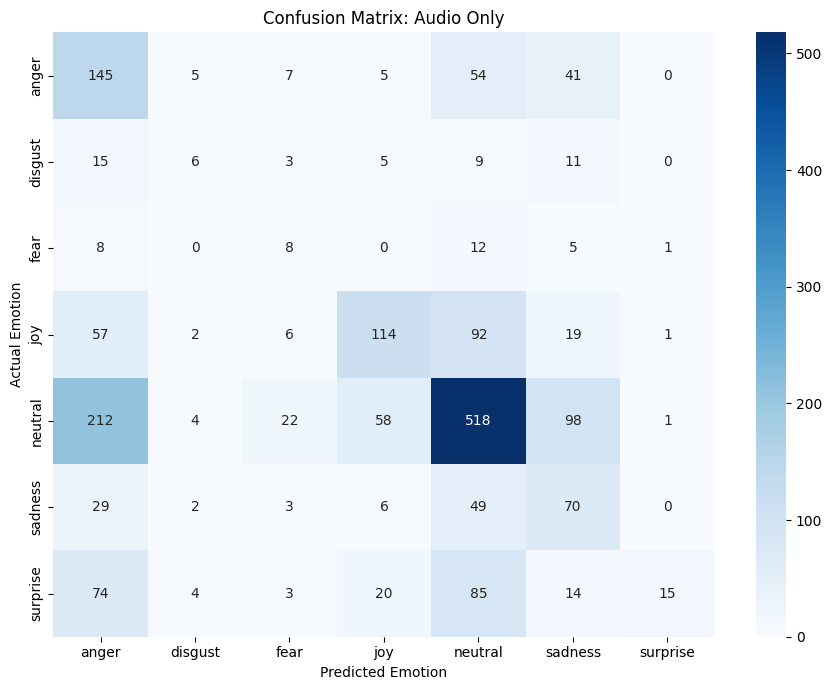

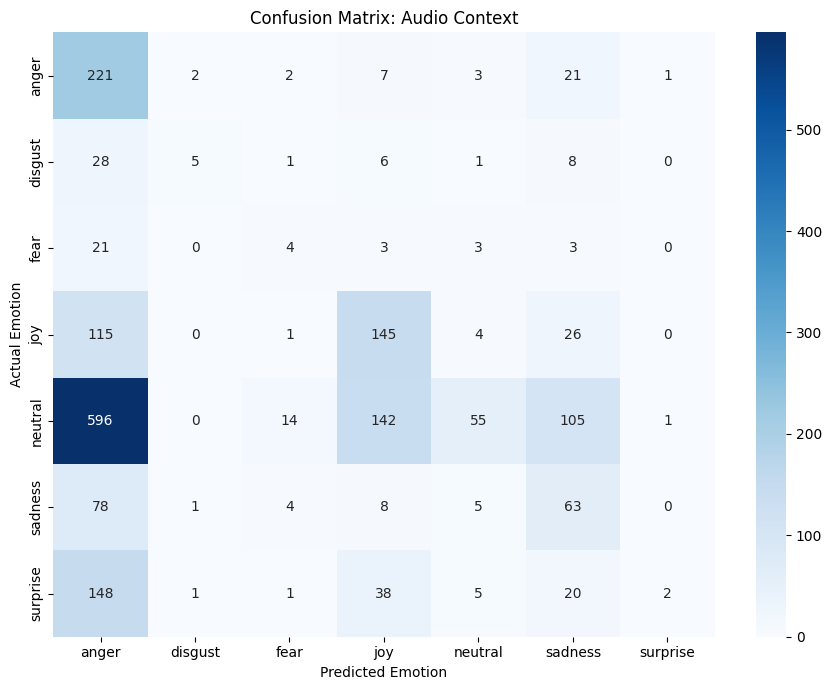

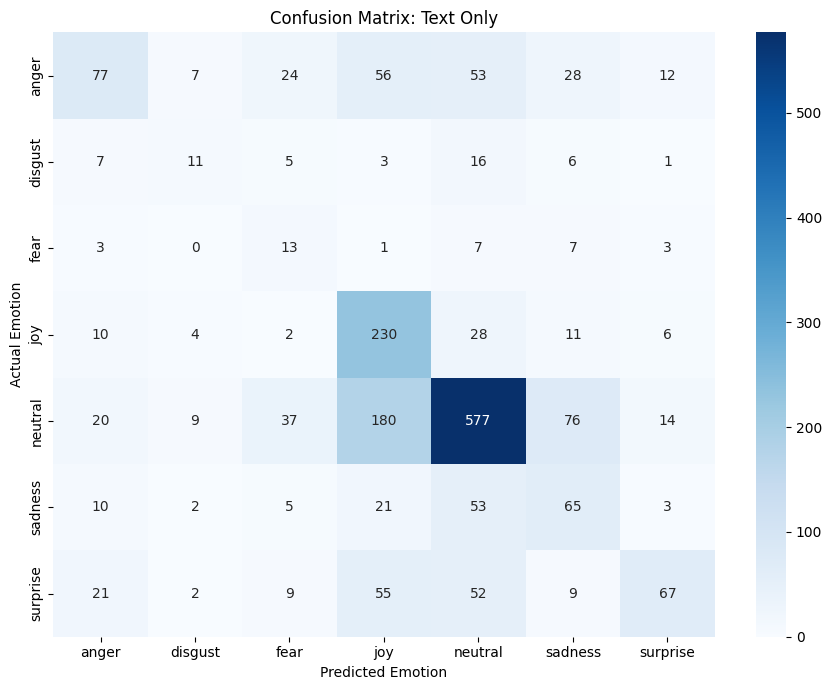

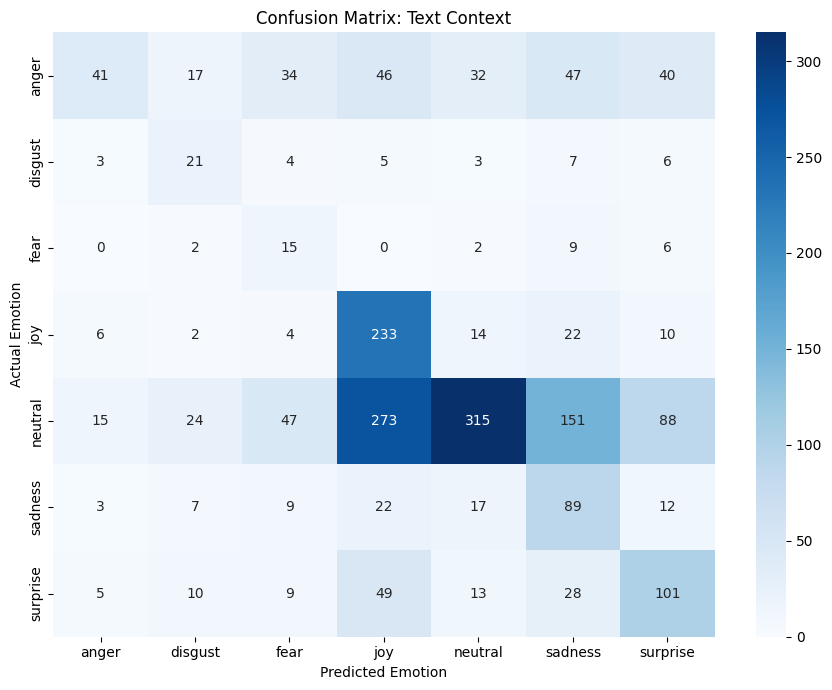

In [6]:

# ============================================
# FIGURE 3: FOUR CONFUSION MATRICES
# ============================================

for condition in CONDITIONS:

    subset = complete[
        complete["condition"] == condition
    ]

    cm = confusion_matrix(
        subset["actual_clean"],
        subset["prediction_clean"],
        labels=LABELS
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABELS,
        yticklabels=LABELS
    )

    plt.title(
        f"Confusion Matrix: {condition.replace('_', ' ').title()}"
    )

    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")
    plt.tight_layout()

    filename = f"figure3_confusion_{condition}.png"

    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


EFFECT OF ADDING CONTEXT


,Metric,Audio_Context_Gain,Text_Context_Gain,Difference_in_Differences
0,Accuracy,-0.1986,-0.1173,-0.0813
1,Macro_Precision,-0.0266,-0.0486,+0.0220
2,Macro_Recall,-0.0496,+0.0222,-0.0718
3,Macro_F1,-0.1053,-0.0475,-0.0578


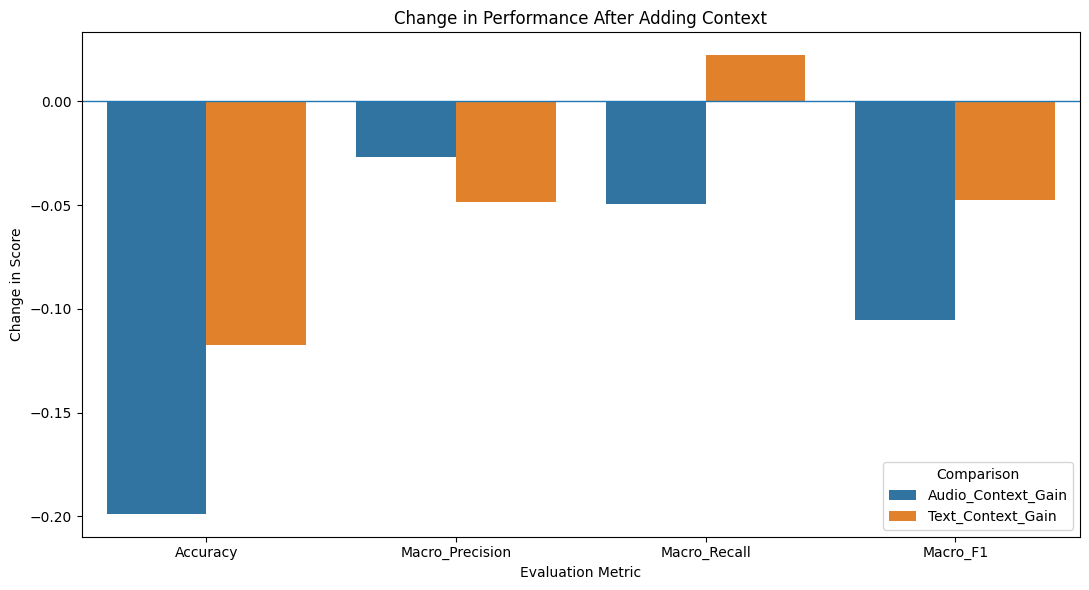

In [7]:

# ============================================
# CONTEXT IMPACT
# ============================================

metric_columns = [
    "Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1"
]

indexed = metrics_df.set_index("Condition")

context_comparison = []

for metric in metric_columns:

    audio_gain = (
        indexed.loc["audio_context", metric] -
        indexed.loc["audio_only", metric]
    )

    text_gain = (
        indexed.loc["text_context", metric] -
        indexed.loc["text_only", metric]
    )

    context_comparison.append({
        "Metric": metric,
        "Audio_Context_Gain": audio_gain,
        "Text_Context_Gain": text_gain,
        "Difference_in_Differences": audio_gain - text_gain
    })

context_df = pd.DataFrame(context_comparison)

print("EFFECT OF ADDING CONTEXT")
display(
    context_df.style.format({
        "Audio_Context_Gain": "{:+.4f}",
        "Text_Context_Gain": "{:+.4f}",
        "Difference_in_Differences": "{:+.4f}"
    })
)

context_df.to_csv(
    os.path.join(OUTPUT_DIR, "context_impact_metrics.csv"),
    index=False
)

# Figure 4: Context impact
context_plot = context_df.melt(
    id_vars="Metric",
    value_vars=[
        "Audio_Context_Gain",
        "Text_Context_Gain"
    ],
    var_name="Comparison",
    value_name="Gain"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=context_plot,
    x="Metric",
    y="Gain",
    hue="Comparison"
)

plt.axhline(0, linewidth=1)
plt.title("Change in Performance After Adding Context")
plt.xlabel("Evaluation Metric")
plt.ylabel("Change in Score")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "figure4_context_impact.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


PREDICTION CHANGES AFTER ADDING CONTEXT


,Modality,Total_Utterances,Predictions_Changed,Predictions_Unchanged,Changed_Percentage,Changed_Became_Correct,Changed_Became_Incorrect,Changed_Remained_Incorrect,Changed_Remained_Correct
0,Audio,1918,1041,877,54.275287,148,529,364,0
1,Text,1918,810,1108,42.231491,155,380,275,0


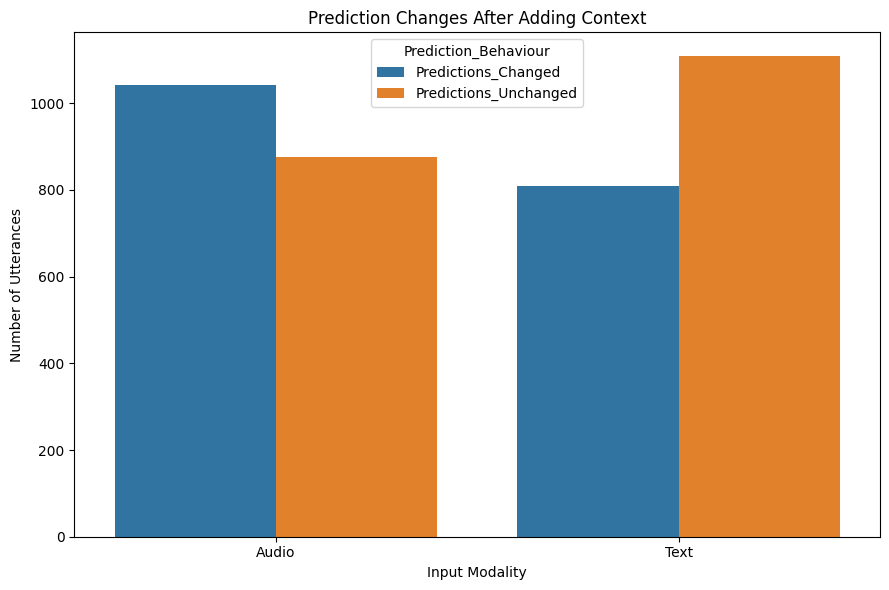

In [8]:

# ============================================
# PREDICTION CHANGES AFTER ADDING CONTEXT
# ============================================

wide = complete.pivot(
    index="target_id",
    columns="condition",
    values="prediction_clean"
)

actuals = (
    complete.drop_duplicates("target_id")
    .set_index("target_id")["actual_clean"]
)

wide["actual"] = actuals

def compare_context(base_col, context_col, modality):

    base_correct = wide[base_col] == wide["actual"]
    context_correct = wide[context_col] == wide["actual"]

    changed = wide[base_col] != wide[context_col]

    results = {
        "Modality": modality,
        "Total_Utterances": len(wide),
        "Predictions_Changed": int(changed.sum()),
        "Predictions_Unchanged": int((~changed).sum()),
        "Changed_Percentage": changed.mean() * 100,
        "Changed_Became_Correct": int(
            (changed & ~base_correct & context_correct).sum()
        ),
        "Changed_Became_Incorrect": int(
            (changed & base_correct & ~context_correct).sum()
        ),
        "Changed_Remained_Incorrect": int(
            (changed & ~base_correct & ~context_correct).sum()
        ),
        "Changed_Remained_Correct": int(
            (changed & base_correct & context_correct).sum()
        )
    }

    return results


change_results = pd.DataFrame([
    compare_context(
        "audio_only",
        "audio_context",
        "Audio"
    ),
    compare_context(
        "text_only",
        "text_context",
        "Text"
    )
])

print("PREDICTION CHANGES AFTER ADDING CONTEXT")
display(change_results)

change_results.to_csv(
    os.path.join(OUTPUT_DIR, "prediction_change_analysis.csv"),
    index=False
)

# Figure 5: Prediction changes
change_plot = change_results.melt(
    id_vars="Modality",
    value_vars=[
        "Predictions_Changed",
        "Predictions_Unchanged"
    ],
    var_name="Prediction_Behaviour",
    value_name="Number_of_Utterances"
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=change_plot,
    x="Modality",
    y="Number_of_Utterances",
    hue="Prediction_Behaviour"
)

plt.title("Prediction Changes After Adding Context")
plt.xlabel("Input Modality")
plt.ylabel("Number of Utterances")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "figure5_prediction_changes.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [9]:

# ============================================
# FINAL OUTPUT CHECK
# ============================================

print("EVALUATION COMPLETED")
print("----------------------------------")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

print("----------------------------------")
print("All results saved in:")
print(OUTPUT_DIR)

print("\nDownload folder as ZIP")

import shutil

zip_path = shutil.make_archive(
    "/content/drive/MyDrive/MELD_Evaluation",
    "zip",
    OUTPUT_DIR
)

print("ZIP file:", zip_path)


EVALUATION COMPLETED
----------------------------------
cleaned_complete_predictions.csv
context_impact_metrics.csv
figure1_overall_performance.png
figure2_emotion_f1.png
figure3_confusion_audio_context.png
figure3_confusion_audio_only.png
figure3_confusion_text_context.png
figure3_confusion_text_only.png
figure4_context_impact.png
figure5_prediction_changes.png
overall_metrics.csv
per_emotion_metrics.csv
prediction_change_analysis.csv
----------------------------------
All results saved in:
/content/drive/MyDrive/MELD_Evaluation

Download folder as ZIP
ZIP file: /content/drive/MyDrive/MELD_Evaluation.zip


In [10]:

import pandas as pd
import os

folder = "/content/drive/MyDrive/MELD_Evaluation"

files = [
    "overall_metrics.csv",
    "context_impact_metrics.csv",
    "prediction_change_analysis.csv",
    "per_emotion_metrics.csv"
]

for file in files:
    print("\n" + "=" * 65)
    print(file.upper())
    print("=" * 65)

    result = pd.read_csv(os.path.join(folder, file))
    print(result.to_string(index=False))



OVERALL_METRICS.CSV
    Condition  Samples  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
   audio_only     1918  0.456726         0.424063      0.341582  0.319447
audio_context     1918  0.258081         0.397437      0.291952  0.214171
    text_only     1918  0.542231         0.440085      0.435607  0.407152
 text_context     1918  0.424922         0.391462      0.457786  0.359654

CONTEXT_IMPACT_METRICS.CSV
         Metric  Audio_Context_Gain  Text_Context_Gain  Difference_in_Differences
       Accuracy           -0.198644          -0.117310                  -0.081335
Macro_Precision           -0.026626          -0.048623                   0.021997
   Macro_Recall           -0.049631           0.022179                  -0.071810
       Macro_F1           -0.105276          -0.047497                  -0.057779

PREDICTION_CHANGE_ANALYSIS.CSV
Modality  Total_Utterances  Predictions_Changed  Predictions_Unchanged  Changed_Percentage  Changed_Became_Correct  Changed_Became_Incorrec